In [2]:
import pandas as pd
df=pd.read_csv("Iris.csv")

In [3]:
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [4]:
df.columns.tolist()

['Id',
 'SepalLengthCm',
 'SepalWidthCm',
 'PetalLengthCm',
 'PetalWidthCm',
 'Species']

In [6]:
df.shape

(150, 6)

In [8]:
df.dtypes

Id                 int64
SepalLengthCm    float64
SepalWidthCm     float64
PetalLengthCm    float64
PetalWidthCm     float64
Species           object
dtype: object

In [9]:
df.isnull().sum()

Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

In [10]:
# Check the number of flowers in each species
print("\nSpecies Distribution:")
print(df["Species"].value_counts())


Species Distribution:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Select the four numerical features
X = df[
    [
        "SepalLengthCm",
        "SepalWidthCm",
        "PetalLengthCm",
        "PetalWidthCm"
    ]
]

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply K-Means clustering
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["Predicted_Cluster"] = kmeans.fit_predict(X_scaled)

# Display the cluster distribution
print("\nCluster Distribution:")
print(df["Predicted_Cluster"].value_counts().sort_index())

# Compare predicted clusters with actual species
print("\nActual Species vs Predicted Clusters:")
print(pd.crosstab(df["Species"], df["Predicted_Cluster"]))


Cluster Distribution:
Predicted_Cluster
0    53
1    50
2    47
Name: count, dtype: int64

Actual Species vs Predicted Clusters:
Predicted_Cluster   0   1   2
Species                      
Iris-setosa         0  50   0
Iris-versicolor    39   0  11
Iris-virginica     14   0  36


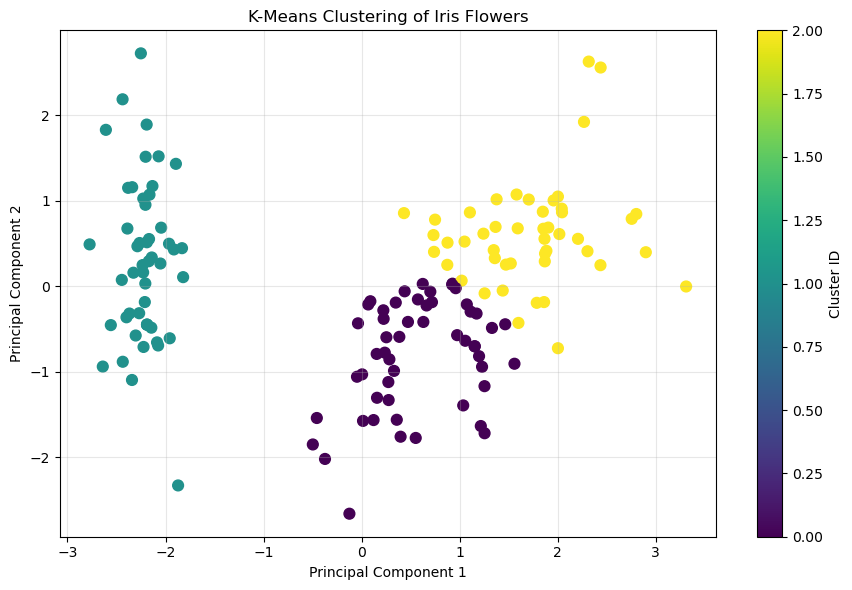

In [12]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Reduce four features to two principal components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Create a scatter plot
plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df["Predicted_Cluster"],
    cmap="viridis",
    s=60
)

plt.title("K-Means Clustering of Iris Flowers")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster ID")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("iris_kmeans_clusters.png", dpi=300)
plt.show()

In [13]:
# Compare actual species with predicted clusters
comparison = pd.crosstab(
    df["Species"],
    df["Predicted_Cluster"],
    rownames=["Actual Species"],
    colnames=["Predicted Cluster"]
)

print("\nActual Species vs Predicted Clusters:")
print(comparison)


Actual Species vs Predicted Clusters:
Predicted Cluster   0   1   2
Actual Species               
Iris-setosa         0  50   0
Iris-versicolor    39   0  11
Iris-virginica     14   0  36


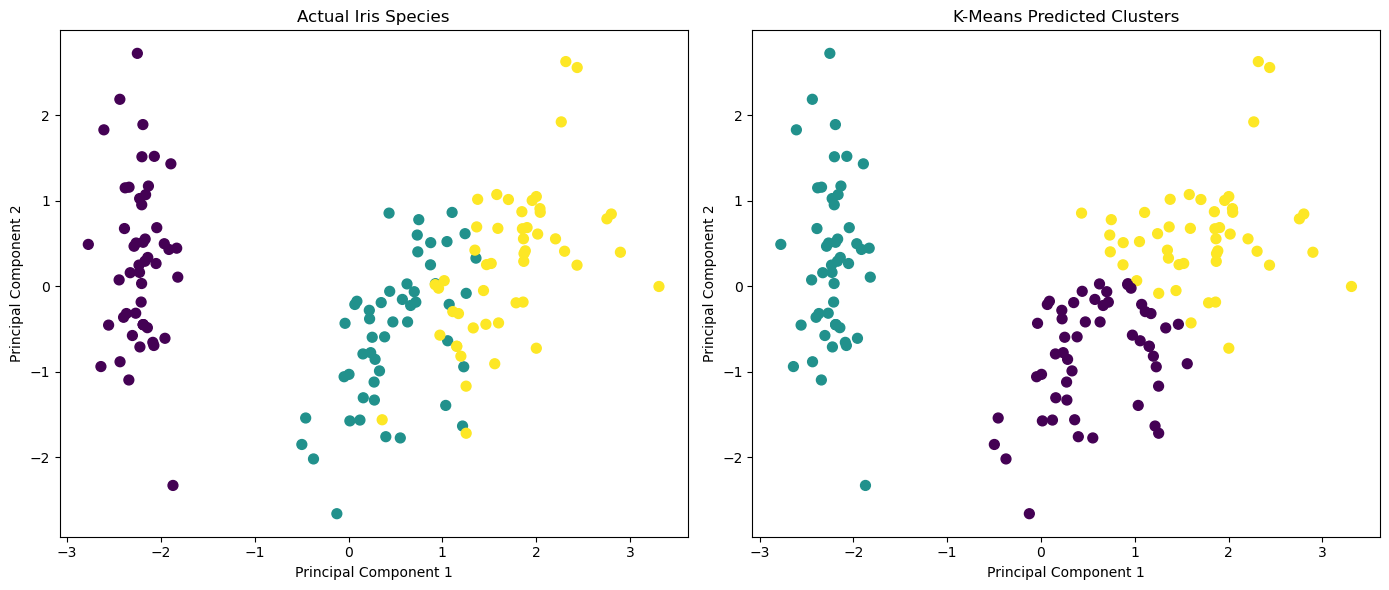

In [14]:
# Create two comparison plots
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot actual species
species_codes = pd.Categorical(df["Species"]).codes

axes[0].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=species_codes,
    cmap="viridis",
    s=50
)

axes[0].set_title("Actual Iris Species")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")

# Plot predicted clusters
axes[1].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df["Predicted_Cluster"],
    cmap="viridis",
    s=50
)

axes[1].set_title("K-Means Predicted Clusters")
axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")

plt.tight_layout()
plt.savefig("iris_species_comparison.png", dpi=300)
plt.show()

In [15]:
# Apply PCA to the standardized features
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Display the reduced dimensions
pca_df = pd.DataFrame(
    X_pca,
    columns=["Principal Component 1", "Principal Component 2"]
)

print("\nPCA Reduced Dataset:")
print(pca_df.head())

print("\nOriginal Shape:", X_scaled.shape)
print("Reduced Shape:", X_pca.shape)

# Display explained variance
print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

print(
    "\nTotal Variance Retained:",
    pca.explained_variance_ratio_.sum() * 100,
    "%"
)


PCA Reduced Dataset:
   Principal Component 1  Principal Component 2
0              -2.264542               0.505704
1              -2.086426              -0.655405
2              -2.367950              -0.318477
3              -2.304197              -0.575368
4              -2.388777               0.674767

Original Shape: (150, 4)
Reduced Shape: (150, 2)

Explained Variance Ratio:
[0.72770452 0.23030523]

Total Variance Retained: 95.80097536148197 %


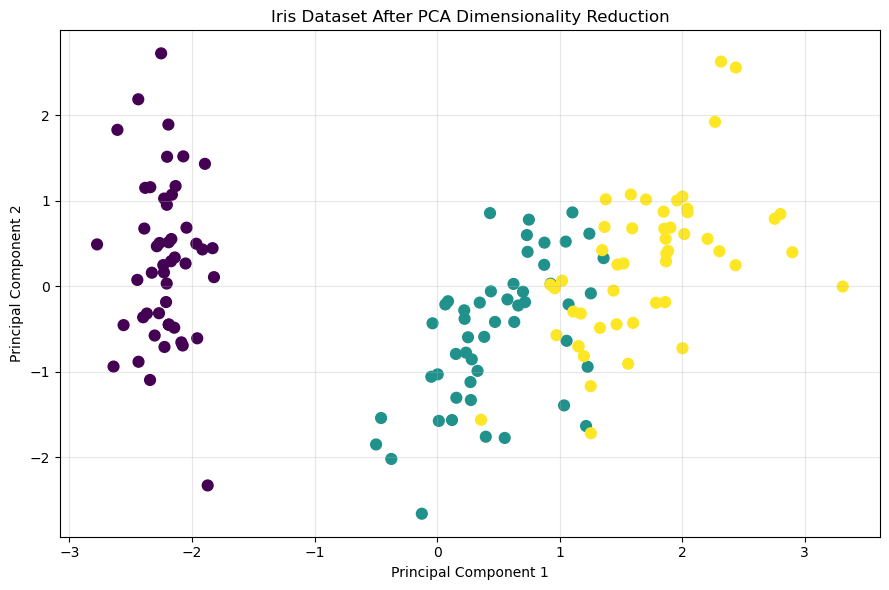

In [16]:
plt.figure(figsize=(9, 6))

plt.scatter(
    pca_df["Principal Component 1"],
    pca_df["Principal Component 2"],
    c=species_codes,
    cmap="viridis",
    s=60
)

plt.title("Iris Dataset After PCA Dimensionality Reduction")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("iris_pca_visualization.png", dpi=300)
plt.show()

In [17]:
from sklearn.metrics import silhouette_score

print("Silhouette Score:", round(silhouette_score(X_scaled, kmeans.labels_), 4))
print("Inertia:", round(kmeans.inertia_, 4))

Silhouette Score: 0.459
Inertia: 140.9658
